# Candle Streaks 01 — Every consecutive five-minute price-sign run

**Historical exploratory research. No arbitrary fixed 10-bar samples.** Walk each asset's entire available five-minute return history sequentially, recording every completed streak (`+1`, `+2`, ... and `−1`, `−2`, ...) and each point where a live streak reaches length `k`. Then test whether the *immediately next nonzero* candle is more or less likely to continue the streak.

The main forecasting controls are **50/50**, empirical unconditional sign frequency, and a **first-order Markov** sign-only model. A streak-length effect is useful only if it beats Markov out of sample. AM-T-HAR-Blend is **not** modified here. [Frozen study protocol](../../discussions/Candle_Streaks/001_chatgpt_candle_streaks_preregistration.md).

## 0 · Environment, reproducibility and synthetic regression tests

In [1]:
import json, os, sys, subprocess, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display
ROOT=Path.cwd().resolve()
while ROOT!=ROOT.parent and not (ROOT/'src'/'data_engineering').is_dir():ROOT=ROOT.parent
assert (ROOT/'src'/'data_engineering').is_dir(),'Open notebook within the cloned GitHub repository'
sys.path.insert(0,str(ROOT/'src'))
load_dotenv(ROOT/'.env')
from data_engineering.modeling import markov_lift_distributions as vd14
from data_engineering.modeling import candle_streaks as cs
cfg=cs.Specification()
HIST=Path(os.environ['DERIBIT_DATA_ROOT'])/'history'/'price_5m'
assert HIST.is_dir(),f'Cannot locate local Binance price history: {HIST}'
OUT=ROOT/'notebooks'/'Candle_Streaks'/'01';OUT.mkdir(parents=True,exist_ok=True)
START=time.monotonic()
pytest_env=os.environ.copy()
pytest_env['PYTHONPATH']=str(ROOT/'src')+os.pathsep+pytest_env.get('PYTHONPATH','')
chk=subprocess.run([sys.executable,'-m','pytest','-q',str(ROOT/'tests'/'test_candle_streaks.py')],
                   cwd=str(ROOT),env=pytest_env,capture_output=True,text=True)
print(chk.stdout[-2500:]);print(chk.stderr[-1000:])
assert chk.returncode==0,'Synthetic tests must pass before analyzing history'
print('Research registration:',json.dumps(cs.registration(),indent=2))

..............                                                           [100%]
14 passed in 3.98s


Research registration: {
  "version": "CS01-0.1.0",
  "assets": [
    "BTC",
    "ETH",
    "SOL",
    "XRP"
  ],
  "cutoff_utc": "2026-10-14T00:00:00Z",
  "train_fraction": 0.6,
  "valid_fraction": 0.2,
  "length_prior": 40.0,
  "logistic_l2": 0.015,
  "bootstrap_reps": 1000,
  "permutation_reps": 100,
  "seed": 2601,
  "status": "HISTORICAL_EXPLORATORY"
}


## 1 · Load **all available** contiguous five-minute close-to-close returns

The frozen cutoff is the start of 2026-10-14 UTC; only completed days through 2026-10-13 are included. The existing VD14 loader handles off-grid observations, duplicates and missing-bar return invalidation. `ASSETS` are BTC/ETH primary and SOL/XRP secondary. Missing/insufficient-history assets appear in `excluded`. No fixed rolling window is used.

In [2]:
raw,excluded=vd14.load_returns(HIST, tuple(cfg.assets),
                               end=pd.Timestamp(cfg.cutoff_utc),min_days=365)
print('Source exclusions:',excluded)
assert {'BTC','ETH'}.issubset(set(raw.underlying.unique())),'BTC and ETH price history required'
assert pd.to_datetime(raw.state_time,utc=True).max()<pd.Timestamp(cfg.cutoff_utc)
print('Loaded asset rows:',raw.groupby('underlying').size().to_dict())
print('Date range:',raw.state_time.min(),raw.state_time.max())
events,runs,quality=cs.build_events_and_runs(raw)
print('Data quality / strict run boundary statistics:')
display(quality)
print('Count of all five-minute observations, consecutive signed opportunities and episode ends:',len(raw),len(events),len(runs))

Source exclusions: {}
Loaded asset rows: {'BTC': 221761, 'ETH': 221761, 'SOL': 221761, 'XRP': 221761}
Date range: 2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00
Data quality / strict run boundary statistics:


,asset,rows,valid_returns,up,down,zero,missing,discontinuities,first_date,last_date
0,BTC,221761,221760,110525,110589,646,1,0,2024-09-01 00:05:00+00:00,2026-10-11 00:05:00+00:00
1,ETH,221761,221760,111076,110180,504,1,0,2024-09-01 00:05:00+00:00,2026-10-11 00:05:00+00:00
2,SOL,221761,221760,108459,108065,5236,1,0,2024-09-01 00:05:00+00:00,2026-10-11 00:05:00+00:00
3,XRP,221761,221760,108045,108715,5000,1,0,2024-09-01 00:05:00+00:00,2026-10-11 00:05:00+00:00


Count of all five-minute observations, consecutive signed opportunities and episode ends: 887044 875654 449026


## 2 · Completed streak distributions and *reached-k* continuation frequencies

A `+3` completed episode is one **maximal** three-up run whose ending is observed. A *reached `+3`* opportunity counts every live run the moment it gets to length 3. The first is a distribution of episode lengths; the second is the causal information available before the next bar. Missing bars right-censor episodes; zero returns end runs but are not up/down. **Both tables preserve all observed streak lengths**, however long.

Full observed signed run-length range by asset (not truncated):


,max_up,max_down,completed_runs,total_runs
underlying,,,,
BTC,15,-18,111959,111960
ETH,13,-15,113157,113158
SOL,15,-16,111962,111963
XRP,14,-13,111944,111945



 BTC short-length excerpt (ALL lengths saved below)


,signed_streak,n_reached,n_next_nonzero,n_continue,n_reverse,n_zero,n_censored,p_continue_given_next_nonzero,wilson95_low,wilson95_high
0,-1,55957,55807,28322,27485,150,0,0.5075,0.5034,0.5116
1,-2,28322,28256,13857,14399,66,0,0.4904,0.4846,0.4962
2,-3,13857,13821,6580,7241,36,0,0.4761,0.4678,0.4844
3,-4,6580,6566,3070,3496,14,0,0.4676,0.4555,0.4796
4,-5,3070,3058,1503,1555,12,0,0.4915,0.4738,0.5092
5,-6,1503,1500,722,778,3,0,0.4813,0.4561,0.5066
6,-7,722,719,317,402,3,0,0.4409,0.4050,0.4774
7,-8,317,317,145,172,0,0,0.4574,0.4034,0.5124
8,-9,145,145,65,80,0,0,0.4483,0.3697,0.5295
9,-10,65,64,27,37,1,0,0.4219,0.3087,0.5439


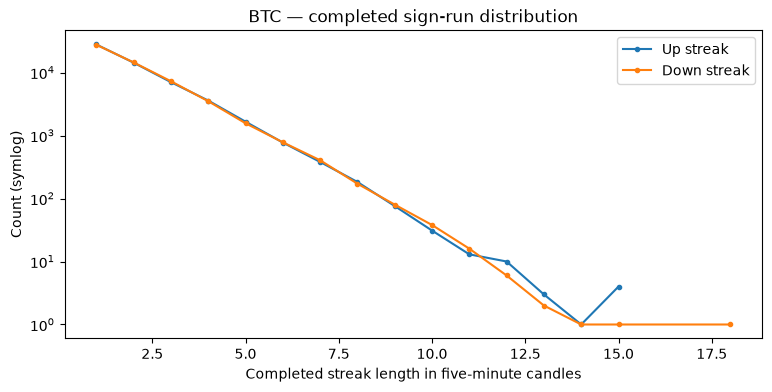


 ETH short-length excerpt (ALL lengths saved below)


,signed_streak,n_reached,n_next_nonzero,n_continue,n_reverse,n_zero,n_censored,p_continue_given_next_nonzero,wilson95_low,wilson95_high
33,-1,56554,56438,28294,28144,116,0,0.5013,0.4972,0.5055
34,-2,28294,28242,13641,14601,52,0,0.4830,0.4772,0.4888
35,-3,13641,13609,6351,7258,31,1,0.4667,0.4583,0.4751
36,-4,6351,6341,2954,3387,10,0,0.4659,0.4536,0.4782
37,-5,2954,2948,1340,1608,6,0,0.4545,0.4366,0.4726
38,-6,1340,1337,574,763,3,0,0.4293,0.4030,0.4560
39,-7,574,574,270,304,0,0,0.4704,0.4299,0.5113
40,-8,270,270,114,156,0,0,0.4222,0.3648,0.4818
41,-9,114,113,53,60,1,0,0.4690,0.3796,0.5605
42,-10,53,53,20,33,0,0,0.3774,0.2594,0.5119


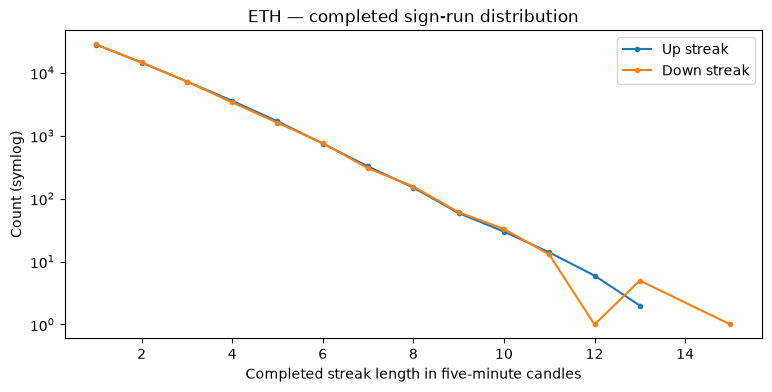


 SOL short-length excerpt (ALL lengths saved below)


,signed_streak,n_reached,n_next_nonzero,n_continue,n_reverse,n_zero,n_censored,p_continue_given_next_nonzero,wilson95_low,wilson95_high
61,-1,56004,54593,27602,26991,1411,0,0.5056,0.5014,0.5098
62,-2,27602,26942,13183,13759,660,0,0.4893,0.4833,0.4953
63,-3,13183,12914,6201,6713,269,0,0.4802,0.4716,0.4888
64,-4,6201,6061,2802,3259,140,0,0.4623,0.4498,0.4749
65,-5,2802,2750,1242,1508,52,0,0.4516,0.4331,0.4703
66,-6,1242,1229,579,650,13,0,0.4711,0.4433,0.4991
67,-7,579,572,259,313,7,0,0.4528,0.4125,0.4938
68,-8,259,250,96,154,9,0,0.3840,0.3259,0.4456
69,-9,96,94,48,46,2,0,0.5106,0.4112,0.6093
70,-10,48,48,24,24,0,0,0.5000,0.3639,0.6361


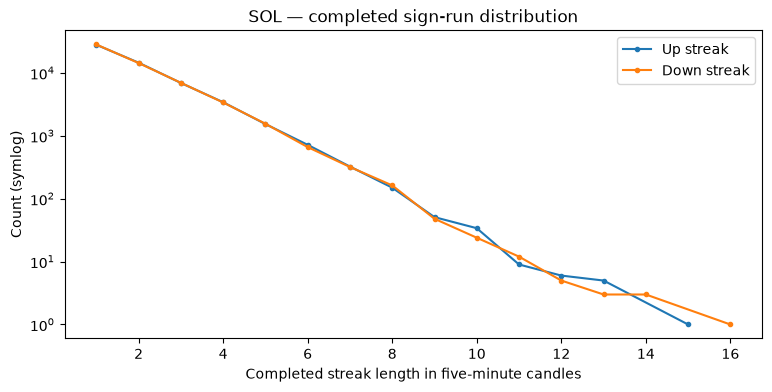


 XRP short-length excerpt (ALL lengths saved below)


,signed_streak,n_reached,n_next_nonzero,n_continue,n_reverse,n_zero,n_censored,p_continue_given_next_nonzero,wilson95_low,wilson95_high
92,-1,56007,54678,27853,26825,1329,0,0.5094,0.5052,0.5136
93,-2,27853,27227,13436,13791,626,0,0.4935,0.4875,0.4994
94,-3,13436,13186,6204,6982,250,0,0.4705,0.4620,0.4790
95,-4,6204,6100,2843,3257,103,1,0.4661,0.4536,0.4786
96,-5,2843,2792,1324,1468,51,0,0.4742,0.4557,0.4928
97,-6,1324,1293,583,710,31,0,0.4509,0.4240,0.4781
98,-7,583,572,259,313,11,0,0.4528,0.4125,0.4938
99,-8,259,258,121,137,1,0,0.4690,0.4090,0.5299
100,-9,121,119,49,70,2,0,0.4118,0.3274,0.5016
101,-10,49,48,24,24,1,0,0.5000,0.3639,0.6361


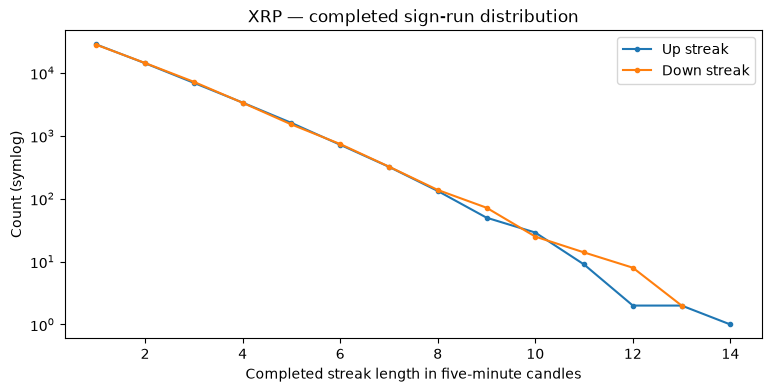

Interpretation: Wilson intervals are pointwise/descriptive; adjacent bars and sessions may be dependent.


In [3]:
# Geometric null uses marginal UP/DOWN/ZERO probabilities of ALL valid bars,
# not sign frequencies conditional on the previous bar being nonzero.
base_rates={(q.asset,sign):float((q.up if sign==1 else q.down)/q.valid_returns)
            for q in quality.itertuples() for sign in (-1,1)}
completed, hazards=cs.distribution_tables(events,runs,base_rates=base_rates)
print('Full observed signed run-length range by asset (not truncated):')
display(runs.groupby('underlying').agg(max_up=('signed_streak','max'),
                                       max_down=('signed_streak','min'),
                                       completed_runs=('completed','sum'),
                                       total_runs=('signed_streak','size')))
for asset in sorted(events.underlying.unique()):
    print('\n',asset,'short-length excerpt (ALL lengths saved below)')
    sample=hazards[(hazards.underlying==asset)&(hazards.length<=12)].copy()
    display(sample[['signed_streak','n_reached','n_next_nonzero','n_continue','n_reverse',
                    'n_zero','n_censored','p_continue_given_next_nonzero','wilson95_low','wilson95_high']].round(4))
    part=completed[completed.underlying==asset]
    fig,ax=plt.subplots(figsize=(9,4))
    for sign,label in [(1,'Up streak'),(-1,'Down streak')]:
        sub=part[part.sign==sign].sort_values('length')
        ax.plot(sub.length,sub.n_completed,marker='.',linestyle='-',label=label)
    ax.set_yscale('symlog',linthresh=1);ax.set_xlabel('Completed streak length in five-minute candles')
    ax.set_ylabel('Count (symlog)');ax.set_title(asset+' — completed sign-run distribution')
    ax.legend();plt.show()
print('Interpretation: Wilson intervals are pointwise/descriptive; adjacent bars and sessions may be dependent.')

## 3 · Independent-sign geometric reference and preserved-zero permutation null

Under an independent 50/50 sign process, the probability of three **specified** up candles is `0.5**3 = 12.5%`, and the probability the NEXT up candle continues a three-up streak remains 50%. For observed data we also calculate sign marginals directly; the approximate geometric expected run count uses observed starts and their empirical same-sign chance. The permutation reference shuffles only nonzero signs, retaining exact zero/missing positions and gaps; it does not preserve clock effects or evolving drift.

In [4]:
print('Specified 3-up prefix under fair independent signs:',.5**3)
for asset in sorted(events.underlying.unique()):
    g=events[(events.underlying==asset)&events.next_valid]
    p_up=np.mean(g.next_sign==1);p_down=np.mean(g.next_sign==-1);p_zero=np.mean(g.next_sign==0)
    print(asset,'next-bar unconditional observed fractions up/down/zero:',round(p_up,5),round(p_down,5),round(p_zero,5))
permutations=cs.iid_permutation_null(raw,reps=cfg.permutation_reps,seed=cfg.seed)
display(permutations.round(3))

Specified 3-up prefix under fair independent signs: 0.125
BTC next-bar unconditional observed fractions up/down/zero: 0.49836 0.49887 0.00277
ETH next-bar unconditional observed fractions up/down/zero: 0.50081 0.49695 0.00225
SOL next-bar unconditional observed fractions up/down/zero: 0.48928 0.48733 0.02339
XRP next-bar unconditional observed fractions up/down/zero: 0.48767 0.49034 0.02199


,asset,metric,tail_min,observed,null_05,null_median,null_95,null_fraction_gte_observed,permutations
0,BTC,max_run,8,18,16.00,18.0,21.10,0.54,100
1,BTC,completed_or_censored_runs_ge_tail,8,638,798.95,844.0,894.15,1.00,100
2,BTC,up_runs_ge_tail,8,321,395.95,424.0,457.00,1.00,100
3,BTC,down_runs_ge_tail,8,317,396.95,424.0,451.05,1.00,100
4,ETH,max_run,8,15,16.00,18.0,21.05,1.00,100
5,ETH,completed_or_censored_runs_ge_tail,8,531,799.75,839.0,893.00,1.00,100
6,ETH,up_runs_ge_tail,8,261,399.75,433.0,463.30,1.00,100
7,ETH,down_runs_ge_tail,8,270,379.00,411.0,439.05,1.00,100
8,SOL,max_run,8,16,15.00,17.0,21.00,0.90,100
9,SOL,completed_or_censored_runs_ge_tail,8,515,702.00,741.5,785.25,1.00,100


## 4 · Chronological forecasting: does **length** add information beyond the last sign?

Chronological full-day split 60% FIT / 20% VALID / 20% TEST. Every model is fitted on FIT ONLY. Forecasting excludes missing/zero next bars and any target crossing a split boundary. All comparisons are made on exactly the same immediate next-nonzero 5-minute candles. A smoothed probability is estimated for **each actually observed signed length**; an unseen `k` falls back to the Markov baseline, never to an arbitrary clipped length. The log-length model is a smoother alternative.

In [5]:
labeled,dates=cs.add_chronological_splits(events,cfg.train_fraction,cfg.valid_fraction)
print('Boundaries:',dates)
print('Scorable opportunities:',labeled.groupby(['underlying','split']).scorable.sum())
models={};scores=[];boot=[];nobs=[]
for asset,g in labeled.groupby('underlying',sort=True):
    tr=g.loc[g.split=='train'];va=g.loc[g.split=='valid'];te=g.loc[g.split=='test']
    if not (tr.scorable.sum()>=100 and va.scorable.sum()>=100 and te.scorable.sum()>=100):
        print('Skipping',asset,': inadequate eligible train/valid/test nonzero next-bar pairs')
        continue
    fit,sc,ci,ct=cs.analyze_asset(tr,va,te,pseudo=cfg.length_prior,
          ridge=cfg.logistic_l2,reps=cfg.bootstrap_reps,seed=cfg.seed)
    models[asset]=fit;sc['asset']=asset;ci['asset']=asset;ct['asset']=asset
    scores.append(sc);boot.append(ci);nobs.append(ct)
score_table=pd.concat(scores,ignore_index=True)
bootstrap=pd.concat(boot,ignore_index=True)
counts=pd.concat(nobs,ignore_index=True)
print('Holdout sign forecast scores (lower logloss/Brier is better):')
display(score_table.sort_values(['asset','period','logloss']).round(7))
print('Paired day bootstrap: streak minus each benchmark (negative = better)')
display(bootstrap.loc[bootstrap.period=='test'].sort_values(['asset','model','reference','metric']).round(7))

Boundaries: {'train_before': '2025-12-07 00:00:00+00:00', 'valid_before': '2026-05-10 00:00:00+00:00', 'n_dates': 771}
Scorable opportunities: underlying  split
BTC         test      43978
            train    132420
            valid     44101
ETH         test      44054
            train    132613
            valid     44089
SOL         test      40687
            train    129514
            valid     41255
XRP         test      41510
            train    128248
            valid     42232
Name: scorable, dtype: int64
Holdout sign forecast scores (lower logloss/Brier is better):


,model,n,logloss,brier,forecast_up_average,realized_up_rate,period,asset
7,markov_sign,43978,0.693121,0.249987,0.499912,0.497249,test,BTC
6,iid_empirical,43978,0.693146,0.250000,0.499909,0.497249,test,BTC
5,random_50,43978,0.693147,0.250000,0.500000,0.497249,test,BTC
9,streak_log_duration,43978,0.693224,0.250038,0.500051,0.497249,test,BTC
8,streak_exact_shrunk,43978,0.693544,0.250198,0.500009,0.497249,test,BTC
4,streak_log_duration,44101,0.692900,0.249876,0.499943,0.501735,valid,BTC
3,streak_exact_shrunk,44101,0.693064,0.249958,0.499877,0.501735,valid,BTC
2,markov_sign,44101,0.693124,0.249989,0.499908,0.501735,valid,BTC
0,random_50,44101,0.693147,0.250000,0.500000,0.501735,valid,BTC
1,iid_empirical,44101,0.693148,0.250000,0.499909,0.501735,valid,BTC


Paired day bootstrap: streak minus each benchmark (negative = better)


,model,reference,metric,mean_day_difference,ci025,ci975,n_days,period,asset
11,streak_exact_shrunk,iid_empirical,brier,0.000132,-0.000081,0.000332,155,test,BTC
10,streak_exact_shrunk,iid_empirical,logloss,0.000264,-0.000181,0.000664,155,test,BTC
9,streak_exact_shrunk,markov_sign,brier,0.000141,-0.000080,0.000343,155,test,BTC
8,streak_exact_shrunk,markov_sign,logloss,0.000282,-0.000174,0.000690,155,test,BTC
15,streak_log_duration,iid_empirical,brier,-0.000024,-0.000193,0.000111,155,test,BTC
14,streak_log_duration,iid_empirical,logloss,-0.000048,-0.000407,0.000232,155,test,BTC
13,streak_log_duration,markov_sign,brier,-0.000015,-0.000192,0.000122,155,test,BTC
12,streak_log_duration,markov_sign,logloss,-0.000030,-0.000399,0.000262,155,test,BTC
27,streak_exact_shrunk,iid_empirical,brier,0.000158,-0.000111,0.000439,155,test,ETH
26,streak_exact_shrunk,iid_empirical,logloss,0.000316,-0.000150,0.000879,155,test,ETH


## 5 · Empirical continuation hazards and economic interpretation checks

The observed geometric null is not inferred from a ten-bar sequence: it's compared with the **entire history of actual runs**. Consider both directions separately. Long streaks have fewer observations and wider uncertainty. The next-nonzero continuation probability is not the same as the unconditional probability for *any* next candle, because flat candles are a third outcome.

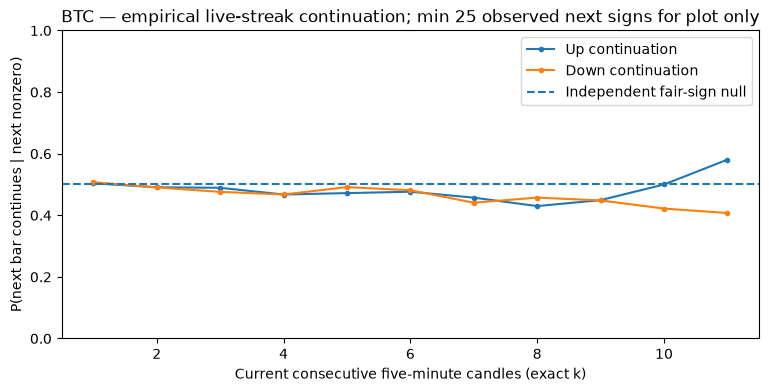

BTC TRAIN-only Markov continuation: {-1: 0.49955452870647216, 1: 0.49937311178247734} | signed log-length coefficient: [-0.07830693929125435, -0.005330611722314339]


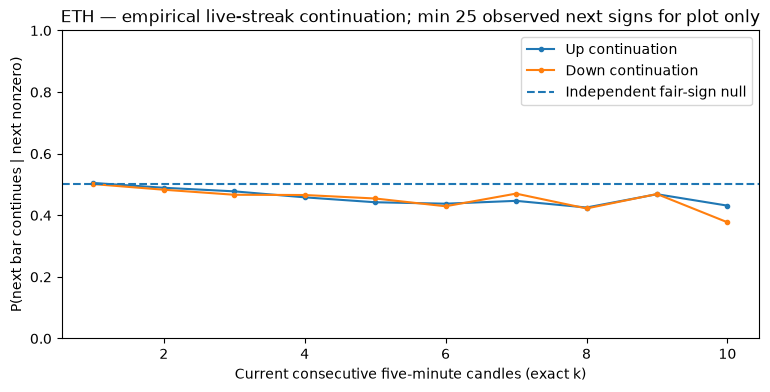

ETH TRAIN-only Markov continuation: {-1: 0.48991500986492637, 1: 0.49644810790558264} | signed log-length coefficient: [-0.08973756800917772, -0.033136876430434406]


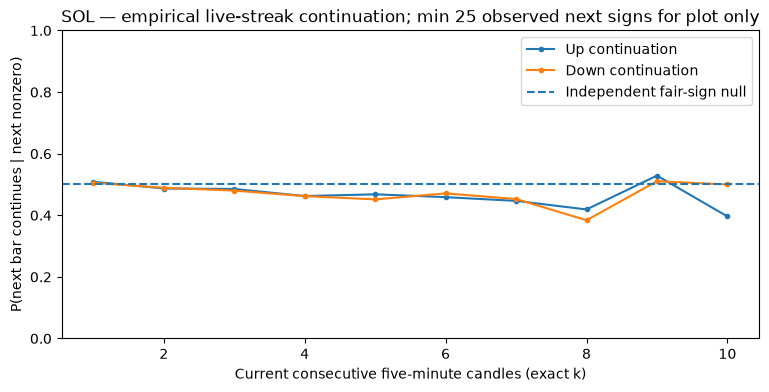

SOL TRAIN-only Markov continuation: {-1: 0.4975024432620263, 1: 0.5018446497471293} | signed log-length coefficient: [-0.08150085190796495, -0.0186422012872377]


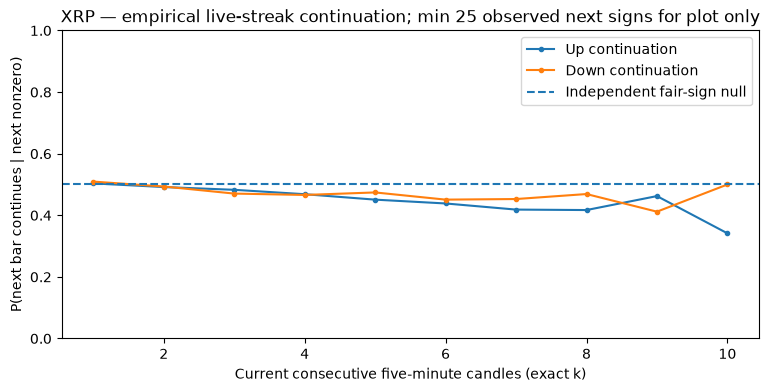

XRP TRAIN-only Markov continuation: {-1: 0.4945966657283163, 1: 0.4982039559619332} | signed log-length coefficient: [-0.0911849753420362, -0.015587822699506466]
The full hazard CSV includes every length, including n<25; plotting threshold is not a data cap.


In [6]:
for asset in sorted(events.underlying.unique()):
    sub=hazards[(hazards.underlying==asset)&(hazards.n_next_nonzero>=25)]
    fig,ax=plt.subplots(figsize=(9,4))
    for sign,label in [(1,'Up continuation'),(-1,'Down continuation')]:
        q=sub[sub.sign==sign].sort_values('length')
        ax.plot(q.length,q.p_continue_given_next_nonzero,marker='.',label=label)
    ax.axhline(.5,linestyle='--',label='Independent fair-sign null')
    ax.set_ylim(0,1);ax.set_xlabel('Current consecutive five-minute candles (exact k)')
    ax.set_ylabel('P(next bar continues | next nonzero)')
    ax.set_title(asset+' — empirical live-streak continuation; min 25 observed next signs for plot only')
    ax.legend();plt.show()
    fit=models.get(asset)
    if fit:
        print(asset,'TRAIN-only Markov continuation:',fit['markov'],
              '| signed log-length coefficient:',fit['logistic_coefficients'][2:])
print('The full hazard CSV includes every length, including n<25; plotting threshold is not a data cap.')

## 6 · Frozen test decision and compact research artifacts

For a candidate useful length effect, at least one fixed length-sensitive model must improve TEST **logloss** over both Markov and marginal-sign benchmarks, and do so for BTC and ETH, with 95% paired-day upper bounds below zero. The empirical distributions are valuable whether or not this forecast gate passes. These historical dates have already been researched in other branches, so even a passing result is exploratory.

In [7]:
decisions=[]
for asset in ('BTC','ETH'):
    bb=bootstrap[(bootstrap.asset==asset)&(bootstrap.period=='test')&(bootstrap.metric=='logloss')]
    options=[]
    for model in ('streak_exact_shrunk','streak_log_duration'):
        candidate=bb[bb.model==model]
        passes=(len(candidate)==2 and (candidate.ci975<0).all())
        options.append({'model':model,'beats_both_benchmarks':bool(passes),
                        'upper95_v_markov':float(candidate.loc[candidate.reference=='markov_sign','ci975'].iloc[0]),
                        'upper95_v_iid':float(candidate.loc[candidate.reference=='iid_empirical','ci975'].iloc[0])})
    decisions.append({'asset':asset,'candidate_models':options})
accepted=any(all(any(z['model']==model and z['beats_both_benchmarks'] for z in d['candidate_models']) for d in decisions)
             for model in ('streak_exact_shrunk','streak_log_duration'))
verdict='HISTORICAL_LENGTH_CANDIDATE' if accepted else 'NO_CONFIRMED_INCREMENTAL_STREAK_SIGNAL'
print('Decision:',verdict)
display(pd.DataFrame(decisions))
output={
 '01_quality.csv':quality,'01_completed_run_lengths.csv':completed,
 '01_reached_length_hazards.csv':hazards,'01_heldout_direction_scores.csv':score_table,
 '01_paired_day_bootstrap.csv':bootstrap,'01_iid_permutation_null.csv':permutations,
 '01_period_counts.csv':counts,
}
for fn,tab in output.items():
    tab.to_csv(OUT/fn,index=False,float_format='%.10g')
serializable={asset:{'p_up':float(f['p_up']),
                        'markov':{str(k):float(v) for k,v in f['markov'].items()},
                        'logistic_coefficients':f['logistic_coefficients'],
                        'training_rows':f['training_rows'],'length_prior':f['pseudo'],
                        'exact_k_levels_fit':len(f['exact']),
                        'max_k_fit':max(k for _,k in f['exact'])} for asset,f in models.items()}
(OUT/'01_fit_summary.json').write_text(json.dumps(serializable,indent=2),encoding='utf-8')
manifest={'module':'Candle_Streaks_01','specification':cs.registration(),
          'source':'Binance spot five-minute close-to-close returns via VD14 load_returns',
          'excluded':excluded,'date_splits':dates,
          'asset_span':quality.to_dict('records'),
          'verdict':verdict,'decisions':decisions,
          'notes':['All observed streak lengths retained; no fixed number of candles per sample.',
                   'Zero returns break runs; binary forecast conditional on next nonzero.',
                   'Gap/file-end right censor, not reversed streaks.',
                   'All models trained on earlier full UTC dates and never refit on evaluation.',
                   'Historical exploratory only; no AM-T-HAR-Blend changes or options trading edge.']}
(OUT/'01_manifest.json').write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
print('Saved',len(output)+2,'aggregate files to',OUT)
print('Elapsed (seconds):',round(time.monotonic()-START,1))

Decision: NO_CONFIRMED_INCREMENTAL_STREAK_SIGNAL


,asset,candidate_models
0,BTC,"[{'model': 'streak_exact_shrunk', 'beats_both_..."
1,ETH,"[{'model': 'streak_exact_shrunk', 'beats_both_..."


Saved 9 aggregate files to D:\Projects\deribit_market_data\notebooks\Candle_Streaks\01
Elapsed (seconds): 33.3


## Interpretation

A long completed streak is **not** proof that the next bar is more likely to reverse. The fair independent-sign process expects increasingly rare long runs even though its next-sign chance is always 50%. The key questions are whether the observed continuation-vs-length curve differs from the independent and first-order Markov references, **and** whether those differences generalize to chronologically later bars. The models score the immediate next **nonzero** five-minute return only; if zero returns are frequent, add a separate three-class forecast in a future registered module. Direction probabilities are not automatically improvements to AM-T-HAR-Blend's return-density forecasts. This project does not change the AM baseline unless a later matched-horizon experiment confirms value.